# Case study: Kelmarsh 1 wind turbine, 2019

A qlPCA analysis of ten-minute SCADA data of one Senvion MM92 turbine at Kelmarsh wind farm (UK). The data set
passed the screening criterion of [`README.md`](README.md) (p = 2, out-of-sample gain of qlPCA over PCA ≥ 5 points).

* Data: Plumley, C. & Takeuchi, R., *Kelmarsh wind farm data*, Zenodo, record 16807551 (2025-08-12),
  doi:10.5281/zenodo.16807551, CC-BY-4.0 (`plumley2025kelmarsh`); turbine Kelmarsh 1, years 2019 (analysis) and
  2018 (knot estimation); downloaded at run time.
* Filtering ([`screening.py`](screening.py)): records overlapping a **Stop** or **Communication** event are removed;
  records with `Power <= 0` are removed; records with missing values are removed. Records overlapping a **Warning**
  event are kept and flagged (`warning_active`, not a model variable); section 8 repeats the comparison without them.
  Sample: 2000 records drawn with `numpy.random.default_rng(2026)`.
* Turbine data (reference only): Senvion, *MM92 — Technical data*, archived product page of 2020-04-02
  ([link](https://web.archive.org/web/20200402094941/https://www.senvion.com/senvion-uk/en/wind-turbines/mm92/); `senvion2020mm92`): cut-in 3 m/s; nominal wind speed 12.5 m/s; nominal power 2,050 kW; rotor
  speed 7.5 – 15 1/min (+12.5 %). No pitch value is given.
* Method: `qlpca` (`lavado2011ijam`, `lavado2012phd`), default mode, p = 2.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import screening as s
from qlpca import QLPCA, ExtrapolationWarning
from qlpca.diagnostics import piecewise_loadings
from qlpca.plots import set_style, biplot, BLUE, ORANGE, INK, INK2, GRID
from qlpca.splines import interior_knots

set_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
RES = HERE / "results"
RES.mkdir(exist_ok=True)
P = 2


def save(fig, stem):
    for ext in ("pdf", "png"):
        fig.savefig(RES / f"{stem}.{ext}", bbox_inches="tight", dpi=150,
                    metadata={"CreationDate": None} if ext == "pdf" else None)


# Senvion MM92 product page (archived 2020-04-02): reference values only
CUT_IN, RATED_WIND, RATED_POWER, ROTOR_MIN, ROTOR_MAX = 3.0, 12.5, 2050.0, 7.5, 15.0

## 1. Data and filtering (2019)

In [2]:
df, info = s.load_kelmarsh(2019)
data = s.sample(df, info, keep_time=True)
mv = info["missing_values"]
print(f"records in 2019: {info['records']}")
print(f"records with missing values: {mv['records_with_missing']} ({mv['share']:.1%}); all nine variables missing: "
      f"{mv['all_variables_missing']}; some missing: {mv['some_variables_missing']} ({mv['some_missing_first']} to "
      f"{mv['some_missing_last']}); during Communication events: {mv['missing_during_communication_events']}")
print(f"step 1, Stop/Communication events {info['events_removed']}: {info['removed_status_events']} records removed "
      f"({info['missing_removed_in_step_1']} of them with missing values)")
print(f"step 2, Power <= 0 or missing: {info['removed_power_le_0']} removed ({info['missing_removed_in_step_2']} with missing power)")
print(f"step 3, missing values: {info['removed_missing']} removed")
print(f"after filtering: {info['records_after_filtering']}; of these overlapping a Warning event: "
      f"{info['records_after_filtering_with_warning_active']}")
print("longest Warning events (kept, flagged):", info["longest_warning_events"][:2])
print(f"sample: 2000 records, {info['sample_first']} to {info['sample_last']}; warning_active: {info['sample_with_warning_active']}")
print("correlation rotor_speed - generator_speed:", round(data["rotor_speed"].corr(data["generator_speed"]), 6))
time = data.pop("time")
warn = data.pop("warning_active").to_numpy()
X = data.drop(columns="generator_speed")
VARS = list(X.columns)
print(len(VARS), "variables:", VARS)

records in 2019: 52560
records with missing values: 2428 (4.6%); all nine variables missing: 84; some missing: 2344 (2019-05-05 03:20:00 to 2019-05-21 09:50:00); during Communication events: 2421
step 1, Stop/Communication events {'Stop': 118, 'Communication': 10}: 2917 records removed (2422 of them with missing values)
step 2, Power <= 0 or missing: 4076 removed (6 with missing power)
step 3, missing values: 0 removed
after filtering: 45567; of these overlapping a Warning event: 8677
longest Warning events (kept, flagged): [{'start': '2019-04-09 10:09:03', 'end': '2019-05-21 10:06:24', 'days': 42.0, 'code': 1860, 'message': 'Oil filter gear choked'}, {'start': '2019-02-24 16:46:28', 'end': '2019-04-04 12:35:45', 'days': 38.8, 'code': 1860, 'message': 'Oil filter gear choked'}]
sample: 2000 records, 2019-01-01 10:20:00 to 2019-12-31 23:00:00; warning_active: 365
correlation rotor_speed - generator_speed: 0.999978
8 variables: ['wind_speed', 'power', 'rotor_speed', 'pitch_angle', 'nacel

* **Missing values** are removed because the gaps come from a technical failure (data not recorded or not
  transmitted: the 16-day gap of 5 – 21 May coincides with a "Data communication unavailable" event), not from the
  values of the variables, and `qlpca` requires complete data.
* **Warning events are no longer removed.** Two "Oil filter gear choked" warnings (code 1860) last 38 and 42 days,
  during which the turbine produced power; removing them would remove about 80 days of normal production. They are
  flagged instead (`warning_active`), shown in the figures and handled by a sensitivity analysis (section 8).
* `generator_speed` is removed (correlation 1.0000 with `rotor_speed` to four decimals). Eight variables remain.

In [3]:
pd.DataFrame({"after filtering": df.time.dt.month.value_counts().reindex(range(1, 13), fill_value=0),
              "of which warning_active": df[df.warning_active].time.dt.month.value_counts().reindex(range(1, 13), fill_value=0),
              "in the sample": time.dt.month.value_counts().reindex(range(1, 13), fill_value=0)}).T

time,1,2,3,4,5,6,7,8,9,10,11,12
after filtering,4053,3765,4194,3946,1818,3835,3761,4149,3868,4229,3684,4265
of which warning_active,4,550,4194,3245,665,0,1,16,2,0,0,0
in the sample,173,151,173,174,90,167,154,192,175,188,165,198


## 2. Control regions estimated on 2018

The boundaries of the control regions are estimated on **2018** (another year, same filter, all filtered records),
so that the knots do not come from the data they are used on.

**Method.** Wind speed in classes of 0.5 m/s; classes with at least 30 records; medians of rotor speed, pitch angle
and power in each class, placed at the class centres. A boundary is the wind speed at which a median crosses a
threshold set at 5 % of the range of that median over the classes (linear interpolation between class centres):

| boundary | median | threshold | crossing |
|---|---|---|---|
| B1: end of minimum rotor speed | rotor speed | min + 5 % of range | first upward crossing |
| B2: rated rotor speed reached | rotor speed | max − 5 % of range | first upward crossing |
| B3: start of pitching | pitch angle | min + 5 % of range | first upward crossing above the wind of the minimum (the medians are positive at very low wind, below 4.5 m/s) |
| B4: rated power reached | power | max − 5 % of range | first upward crossing |

**Knots.** Each boundary gives a knot to wind speed (its wind value) and to power (the power median at that wind):
both change across all regions. Rotor speed gets knots at B1 and B2 (the threshold values), where its regime
changes; pitch gets knots at B3 (threshold) and B4 (pitch median at B4). Temperatures: 2 knots at the percentiles.

In [4]:
d18, info18 = s.load_kelmarsh(2018)
print(f"2018: {info18['records']} records, {info18['records_after_filtering']} after filtering")
edges = np.arange(0, 26.0 + 0.5, 0.5)
g = d18.assign(cls=pd.cut(d18.wind_speed, edges, right=False)).groupby("cls", observed=True)
med = g.agg(n=("power", "size"), power=("power", "median"), rotor_speed=("rotor_speed", "median"),
            pitch_angle=("pitch_angle", "median"))
med = med[med.n >= 30]
med.index = [iv.left + 0.25 for iv in med.index]
med.index.name = "class centre (m/s)"
med.to_csv(RES / "case_control_regions_2018_medians.csv", float_format="%.4f", lineterminator="\n")


def crossing(y, thr, start=None):
    # first wind speed (class centres, linear interpolation) at which y rises through thr, from `start` on
    w = y.index.to_numpy(); v = y.to_numpy()
    i0 = 0 if start is None else int(np.searchsorted(w, start))
    for i in range(max(i0, 1), len(v)):
        if v[i - 1] < thr <= v[i]:
            return w[i - 1] + (thr - v[i - 1]) / (v[i] - v[i - 1]) * (w[i] - w[i - 1])
    raise ValueError("no crossing")


r, pt, pw = med.rotor_speed, med.pitch_angle, med.power
thr = {"B1": r.min() + 0.05 * (r.max() - r.min()), "B2": r.max() - 0.05 * (r.max() - r.min()),
       "B3": pt.min() + 0.05 * (pt.max() - pt.min()), "B4": pw.max() - 0.05 * (pw.max() - pw.min())}
B = {"B1": crossing(r, thr["B1"]), "B2": crossing(r, thr["B2"]),
     "B3": crossing(pt, thr["B3"], start=pt.idxmin()), "B4": crossing(pw, thr["B4"])}
at = lambda col, w: float(np.interp(w, med.index, med[col]))
bounds = pd.DataFrame({
    "boundary": ["B1: end of minimum rotor speed", "B2: rated rotor speed reached", "B3: start of pitching",
                 "B4: rated power reached"],
    "threshold": [f"rotor {thr['B1']:.3f} rpm", f"rotor {thr['B2']:.3f} rpm", f"pitch {thr['B3']:.3f} deg",
                  f"power {thr['B4']:.1f} kW"],
    "wind (m/s)": [B[k] for k in B], "power median (kW)": [at("power", B[k]) for k in B],
    "rotor median (rpm)": [at("rotor_speed", B[k]) for k in B], "pitch median (deg)": [at("pitch_angle", B[k]) for k in B]})
bounds.to_csv(RES / "case_control_region_boundaries.csv", index=False, float_format="%.4f", lineterminator="\n")
bounds

2018: 52560 records, 45331 after filtering


,boundary,threshold,wind (m/s),power median (kW),rotor median (rpm),pitch median (deg)
0,B1: end of minimum rotor speed,rotor 8.492 rpm,4.3514,149.0855,8.4915,0.0785
1,B2: rated rotor speed reached,rotor 14.813 rpm,8.6249,1293.2493,14.8135,0.0499
2,B3: start of pitching,pitch 0.713 deg,9.5533,1645.9157,15.1004,0.7130
3,B4: rated power reached,power 1949.0 kW,10.7713,1949.0434,15.1550,3.3324


In [5]:
CONTROL = {"wind_speed": sorted(B.values()),
           "power": sorted(at("power", B[k]) for k in B),
           "rotor_speed": [thr["B1"], thr["B2"]],
           "pitch_angle": [thr["B3"], at("pitch_angle", B["B4"])]}
DATASHEET = {"wind_speed": [CUT_IN, RATED_WIND], "power": [RATED_POWER], "rotor_speed": [ROTOR_MIN, ROTOR_MAX],
             "pitch_angle": []}
pd.DataFrame({v: pd.Series({"control regions (2018)": np.round(CONTROL[v], 3).tolist(),
                            "datasheet (reference)": DATASHEET[v]}) for v in CONTROL}).T

,control regions (2018),datasheet (reference)
wind_speed,"[4.351, 8.625, 9.553, 10.771]","[3.0, 12.5]"
power,"[149.085, 1293.249, 1645.916, 1949.043]",[2050.0]
rotor_speed,"[8.492, 14.813]","[7.5, 15.0]"
pitch_angle,"[0.713, 3.332]",[]


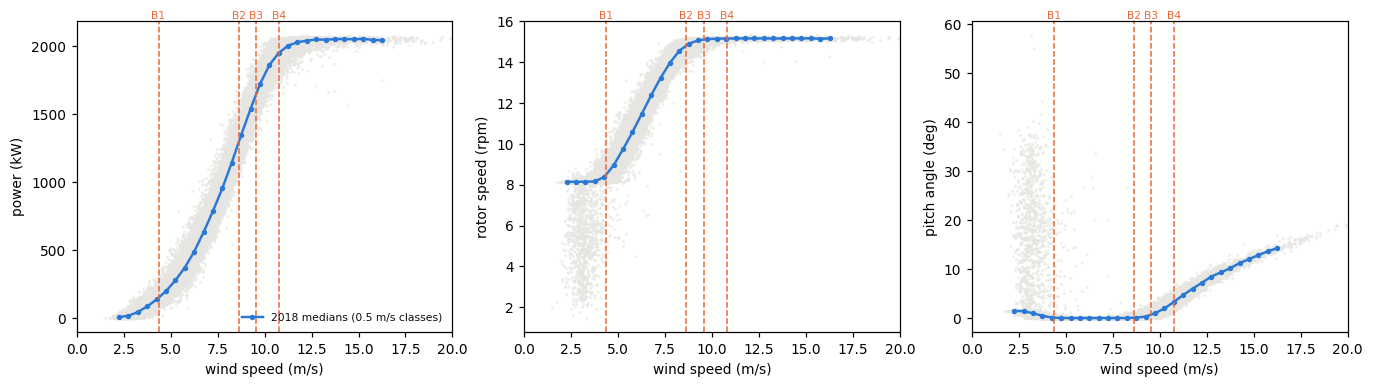

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, col, lab in zip(axes, ("power", "rotor_speed", "pitch_angle"), ("power (kW)", "rotor speed (rpm)", "pitch angle (deg)")):
    ax.scatter(d18.wind_speed, d18[col], s=1, color=GRID, alpha=0.5, rasterized=True)
    ax.plot(med.index, med[col], color=BLUE, lw=1.6, marker="o", ms=2.5, label="2018 medians (0.5 m/s classes)")
    ax.set_xlim(0, 20)
    for k, w in B.items():
        ax.axvline(w, color=ORANGE, lw=1.0, ls="--")
        ax.text(w, ax.get_ylim()[1], k, color=ORANGE, fontsize=7, ha="center", va="bottom")
    ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel(lab)
axes[0].legend(fontsize=7, frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "case_control_regions_2018")
plt.show()

## 3. 2019 data by control region

Regions from the 2018 boundaries on wind speed. Records overlapping a Warning event are drawn with black edges.
Dotted grey lines: Senvion datasheet values (cut-in, nominal wind; 2050 kW; 7.5 and 15 rpm).

,records,warning_active
R1 < B1 (minimum rotor speed),348,95
R2 B1-B2 (variable rotor speed),1304,189
R3 B2-B3 (rated rotor speed),129,20
"R4 B3-B4 (pitching, below rated power)",104,23
R5 >= B4 (rated power),115,38


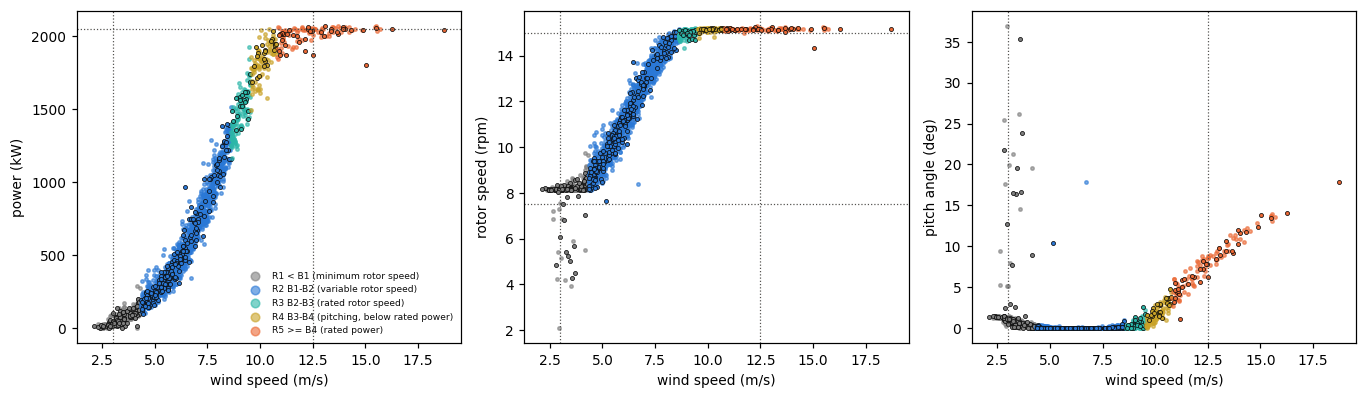

In [7]:
REG = ["R1 < B1 (minimum rotor speed)", "R2 B1-B2 (variable rotor speed)", "R3 B2-B3 (rated rotor speed)",
       "R4 B3-B4 (pitching, below rated power)", "R5 >= B4 (rated power)"]
region = pd.Series(pd.cut(X.wind_speed, [-np.inf, *sorted(B.values()), np.inf], right=False, labels=REG))
RCOL = dict(zip(REG, ["#7f7f7f", BLUE, "#2bb6a8", "#c9a227", ORANGE]))
display(pd.DataFrame({"records": region.value_counts().reindex(REG),
                      "warning_active": pd.Series(warn).groupby(region.to_numpy(), observed=False).sum().reindex(REG)}))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.7))
for ax, col, lab in zip(axes, ("power", "rotor_speed", "pitch_angle"), ("power (kW)", "rotor speed (rpm)", "pitch angle (deg)")):
    for rg in REG:
        sel = (region == rg).to_numpy()
        ax.scatter(X.wind_speed[sel & ~warn], X[col][sel & ~warn], s=5, color=RCOL[rg], alpha=0.6, label=rg)
        ax.scatter(X.wind_speed[sel & warn], X[col][sel & warn], s=7, color=RCOL[rg], edgecolor=INK, linewidth=0.5)
    for v in (CUT_IN, RATED_WIND):
        ax.axvline(v, color=INK2, lw=0.8, ls=":")
    if col == "power":
        ax.axhline(RATED_POWER, color=INK2, lw=0.8, ls=":")
    if col == "rotor_speed":
        for v in (ROTOR_MIN, ROTOR_MAX):
            ax.axhline(v, color=INK2, lw=0.8, ls=":")
    ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel(lab)
axes[0].legend(fontsize=6, frameon=False, markerscale=2.5, loc="lower right")
fig.tight_layout()
save(fig, "case_operating_regimes")
plt.show()

## 4. Models and VAF (p = 2)

* **PCA** (`n_knots=0`).
* **percentile knots**: `QLPCA(n_knots=2)`, knots at the percentiles of the training data.
* **control regions (2018)**: `knots=` from section 2 for wind, power, rotor and pitch; temperatures at the
  percentiles of the training data.
* both also with `monotone=True`;
* **datasheet (reference)**: wind 3 and 12.5 m/s, power 2050 kW, rotor 7.5 and 15 rpm, pitch none, temperatures at
  percentiles.

In-sample VAF on the 2000 records; out-of-sample VAF over 5 contiguous time blocks with the criterion of
`screening.py`; the gain over PCA is paired by block (mean and standard error over the 5 blocks).

In [8]:
def knots_from(table, Xtr):
    Xtr = pd.DataFrame(np.asarray(Xtr), columns=VARS)
    return [np.asarray(table[v], float) if v in table else interior_knots(Xtr[v].to_numpy(), 2) for v in VARS]


SPECS = {
    "PCA": lambda Xtr: dict(n_knots=0),
    "percentile knots": lambda Xtr: dict(n_knots=2),
    "percentile knots, monotone": lambda Xtr: dict(n_knots=2, monotone=True),
    "control regions (2018)": lambda Xtr: dict(knots=knots_from(CONTROL, Xtr)),
    "control regions (2018), monotone": lambda Xtr: dict(knots=knots_from(CONTROL, Xtr), monotone=True),
    "datasheet (reference)": lambda Xtr: dict(knots=knots_from(DATASHEET, Xtr)),
}


def fit(name, Xtr):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return QLPCA(n_components=P, random_state=0, **SPECS[name](Xtr)).fit(Xtr)


def vaf_table(Xd, label):
    A = Xd.to_numpy()
    blocks = np.array_split(np.arange(len(A)), 5)
    oos = {name: [] for name in SPECS}
    for te in blocks:
        tr = np.setdiff1d(np.arange(len(A)), te)
        for name in SPECS:
            oos[name].append(s.oos_vaf(A, fit(name, A[tr]), A[te], A[tr]))
    oos = {k: np.array(v) for k, v in oos.items()}
    rows = []
    for name in SPECS:
        gain = oos[name] - oos["PCA"]
        rows.append({"data": label, "model": name, "VAF in sample": fit(name, Xd).vaf_.sum(),
                     "VAF out of sample": oos[name].mean(), "se": oos[name].std(ddof=1) / np.sqrt(5),
                     "paired gain": np.nan if name == "PCA" else gain.mean(),
                     "se (gain)": np.nan if name == "PCA" else gain.std(ddof=1) / np.sqrt(5)})
    return pd.DataFrame(rows), pd.DataFrame(oos), blocks


vaf, oos_blocks, blocks = vaf_table(X, "all 2000 records")
vaf.to_csv(RES / "case_vaf.csv", index=False, float_format="%.4f", lineterminator="\n")
oos_blocks.index = [f"block {i + 1} ({time.iloc[b[0]]:%Y-%m-%d} to {time.iloc[b[-1]]:%Y-%m-%d})" for i, b in enumerate(blocks)]
oos_blocks.to_csv(RES / "case_vaf_blocks.csv", float_format="%.4f", lineterminator="\n")
models = {name: fit(name, X) for name in SPECS}
vaf.drop(columns="data").set_index("model")

,VAF in sample,VAF out of sample,se,paired gain,se (gain)
model,,,,,
PCA,72.5739,71.9493,4.0124,NaN,NaN
percentile knots,80.6315,80.4770,2.1032,8.5277,1.9701
"percentile knots, monotone",78.8672,78.3424,3.1649,6.3931,1.0073
control regions (2018),83.4467,82.9144,2.1592,10.9651,2.1453
"control regions (2018), monotone",82.6426,81.9673,2.5506,10.0180,1.8003
datasheet (reference),76.1492,75.8875,4.1463,3.9382,0.3245


In [9]:
oos_blocks.round(2)

,PCA,percentile knots,"percentile knots, monotone",control regions (2018),"control regions (2018), monotone",datasheet (reference)
block 1 (2019-01-01 to 2019-03-13),80.92,85.28,85.94,88.62,88.78,85.56
block 2 (2019-03-13 to 2019-06-07),59.11,73.14,67.60,75.30,73.12,62.42
block 3 (2019-06-07 to 2019-08-17),73.16,81.02,78.74,83.43,82.24,76.28
block 4 (2019-08-17 to 2019-10-25),67.29,79.31,76.31,82.76,81.50,71.97
block 5 (2019-10-26 to 2019-12-31),79.27,83.63,83.12,84.46,84.20,83.20


### Knots compared: percentiles (2019 sample) and control-region boundaries (2018)

For wind, power, rotor and pitch: the interior knots each model actually uses (after merging coinciding knots), and
for every percentile knot the distance to the nearest control-region knot, in the units of the variable and in
standard deviations of the 2019 sample.

In [10]:
mp, mc, mdsh = models["percentile knots"], models["control regions (2018)"], models["datasheet (reference)"]
interior = lambda m, j: (np.unique(m.knots_[j])[1:-1] * m.std_[j] + m.mean_[j])
rows = []
for v in CONTROL:
    j = VARS.index(v)
    kp, kc = interior(mp, j), interior(mc, j)
    if len(kp) == 0:
        rows.append({"variable": v, "percentile knot": np.nan})
    for k in kp:
        i = np.abs(kc - k).argmin()
        rows.append({"variable": v, "percentile knot": k, "nearest control-region knot": kc[i],
                     "distance": abs(kc[i] - k), "distance (sd)": abs(kc[i] - k) / X[v].std()})
knot_dist = pd.DataFrame(rows)
knot_dist.to_csv(RES / "case_knot_distances.csv", index=False, float_format="%.4f", lineterminator="\n")
print("interior knots used:")
for v in CONTROL:
    j = VARS.index(v)
    print(f"  {v:12s} percentiles {np.round(interior(mp, j), 3).tolist()}  control regions {np.round(interior(mc, j), 3).tolist()}"
          f"  datasheet {np.round(interior(mdsh, j), 3).tolist()}")
knot_dist

interior knots used:
  wind_speed   percentiles [5.277, 7.224]  control regions [4.351, 8.625, 9.553, 10.771]  datasheet [3.0, 12.5]
  power        percentiles [285.12, 781.411]  control regions [149.085, 1293.249, 1645.916, 1949.043]  datasheet [2050.0]
  rotor_speed  percentiles [9.78, 13.231]  control regions [8.492, 14.813]  datasheet [7.5, 15.0]
  pitch_angle  percentiles [0.11]  control regions [0.713, 3.332]  datasheet []


,variable,percentile knot,nearest control-region knot,distance,distance (sd)
0,wind_speed,5.2775,4.3514,0.9261,0.3822
1,wind_speed,7.2239,8.6249,1.4010,0.5782
2,power,285.1196,149.0855,136.0341,0.2285
3,power,781.4106,1293.2493,511.8387,0.8597
4,rotor_speed,9.7803,8.4915,1.2888,0.4931
5,rotor_speed,13.2313,14.8135,1.5822,0.6054
6,pitch_angle,0.1100,0.7130,0.6030,0.2115


### Records per segment

Number of records of the 2000-record sample in each segment between consecutive knots; segments with fewer than
50 records are flagged.

In [11]:
rows = []
for name in ("percentile knots", "control regions (2018)", "datasheet (reference)"):
    m = models[name]
    for j, v in enumerate(VARS):
        e = np.unique(m.knots_[j]) * m.std_[j] + m.mean_[j]
        h = X[v].to_numpy()
        for k in range(len(e) - 1):
            n = int(((h >= e[k] - 1e-9) & (h <= e[k + 1] + 1e-9)).sum())
            rows.append({"model": name, "variable": v, "segment": f"[{e[k] + 0.0:.3f}, {e[k + 1] + 0.0:.3f}]", "n": n,
                         "fewer than 50": "yes" if n < 50 else ""})
seg = pd.DataFrame(rows)
seg.to_csv(RES / "case_segment_counts.csv", index=False, lineterminator="\n")
print("segments with fewer than 50 records:", seg.groupby("model")["fewer than 50"].apply(lambda x: (x == "yes").sum()).to_dict())
seg[seg.variable.isin(list(CONTROL))]

segments with fewer than 50 records: {'control regions (2018)': 0, 'datasheet (reference)': 3, 'percentile knots': 0}


,model,variable,segment,n,fewer than 50
0,percentile knots,wind_speed,"[2.123, 5.277]",660,
1,percentile knots,wind_speed,"[5.277, 7.224]",680,
2,percentile knots,wind_speed,"[7.224, 18.723]",660,
3,percentile knots,power,"[1.236, 285.120]",660,
4,percentile knots,power,"[285.120, 781.411]",680,
5,percentile knots,power,"[781.411, 2069.953]",660,
6,percentile knots,rotor_speed,"[2.088, 9.780]",660,
7,percentile knots,rotor_speed,"[9.780, 13.231]",680,
8,percentile knots,rotor_speed,"[13.231, 15.299]",660,
9,percentile knots,pitch_angle,"[0.000, 0.110]",1340,


## 5. V-shaped transformations

Records on the decreasing segments of `wind_speed`, `power` and `rotor_speed` for the percentile model and for the
control-region model: how many, in which months, the values of the other variables there, and how many are
`warning_active`. Reported as observed.

In [12]:
def decreasing_masks(m):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        pl = piecewise_loadings(m, X)
    out = {}
    for v in ("wind_speed", "power", "rotor_speed"):
        j = VARS.index(v); e = pl[j]["edges"]
        mask = np.zeros(len(X), bool)
        segs = []
        for k, sg in enumerate(pl[j]["slope_sign"]):
            if sg < 0:
                mask |= (X[v] >= e[k] - 1e-9).to_numpy() & (X[v] <= e[k + 1] + 1e-9).to_numpy()
                segs.append((round(float(e[k]), 3), round(float(e[k + 1]), 3)))
        out[v] = (mask, segs)
    return out


dec = {name: decreasing_masks(models[name]) for name in ("percentile knots", "control regions (2018)")}
for name in dec:
    for v, (m, segs) in dec[name].items():
        print(f"{name:24s} {v:12s} decreasing segment(s) {segs}: {m.sum()} records, warning_active {int((m & warn).sum())}")

percentile knots         wind_speed   decreasing segment(s) [(2.123, 5.277)]: 660 records, warning_active 151
percentile knots         power        decreasing segment(s) [(1.236, 285.12)]: 660 records, warning_active 153
percentile knots         rotor_speed  decreasing segment(s) [(2.088, 9.78)]: 660 records, warning_active 152
control regions (2018)   wind_speed   decreasing segment(s) [(2.123, 4.351)]: 348 records, warning_active 95
control regions (2018)   power        decreasing segment(s) [(1.236, 149.085)]: 356 records, warning_active 96
control regions (2018)   rotor_speed  decreasing segment(s) [(2.088, 8.492)]: 357 records, warning_active 97


In [13]:
for name in dec:
    months = pd.DataFrame({v: pd.Series(time[m].dt.month).value_counts().reindex(range(1, 13), fill_value=0)
                           for v, (m, _) in dec[name].items()})
    months["all records"] = time.dt.month.value_counts().reindex(range(1, 13), fill_value=0)
    print(name)
    display(months.T)

percentile knots


time,1,2,3,4,5,6,7,8,9,10,11,12
wind_speed,59,41,48,89,33,65,68,52,50,65,48,42
power,53,39,50,86,34,59,74,56,47,68,51,43
rotor_speed,56,39,49,86,34,59,73,53,47,68,52,44
all records,173,151,173,174,90,167,154,192,175,188,165,198


control regions (2018)


time,1,2,3,4,5,6,7,8,9,10,11,12
wind_speed,28,15,26,59,20,29,47,29,23,31,25,16
power,27,17,26,58,20,33,47,32,21,32,28,15
rotor_speed,28,18,27,58,19,30,47,31,24,32,27,16
all records,173,151,173,174,90,167,154,192,175,188,165,198


In [14]:
comp = {}
for name in dec:
    m = dec[name]["wind_speed"][0]
    if m.any():
        comp[(name, "decreasing wind segment")] = X[m].median()
        comp[(name, "other records")] = X[~m].median()
pd.DataFrame(comp).round(2)

percentile knots                control regions (2018)              
               decreasing wind segment other records decreasing wind segment other records
wind_speed                        4.26          7.17                    3.52          6.68
power                           140.29        767.22                   73.07        614.38
rotor_speed                       8.39         13.17                    8.15         12.30
pitch_angle                       0.12          0.00                    0.59          0.00
nacelle_temp                     23.72         21.29                   23.72         21.85
generator_temp                   61.09         62.69                   60.91         62.43
gearbox_temp                     56.33         54.25                   54.75         54.95
ambient_temp                     11.69         10.40                   12.20         10.52

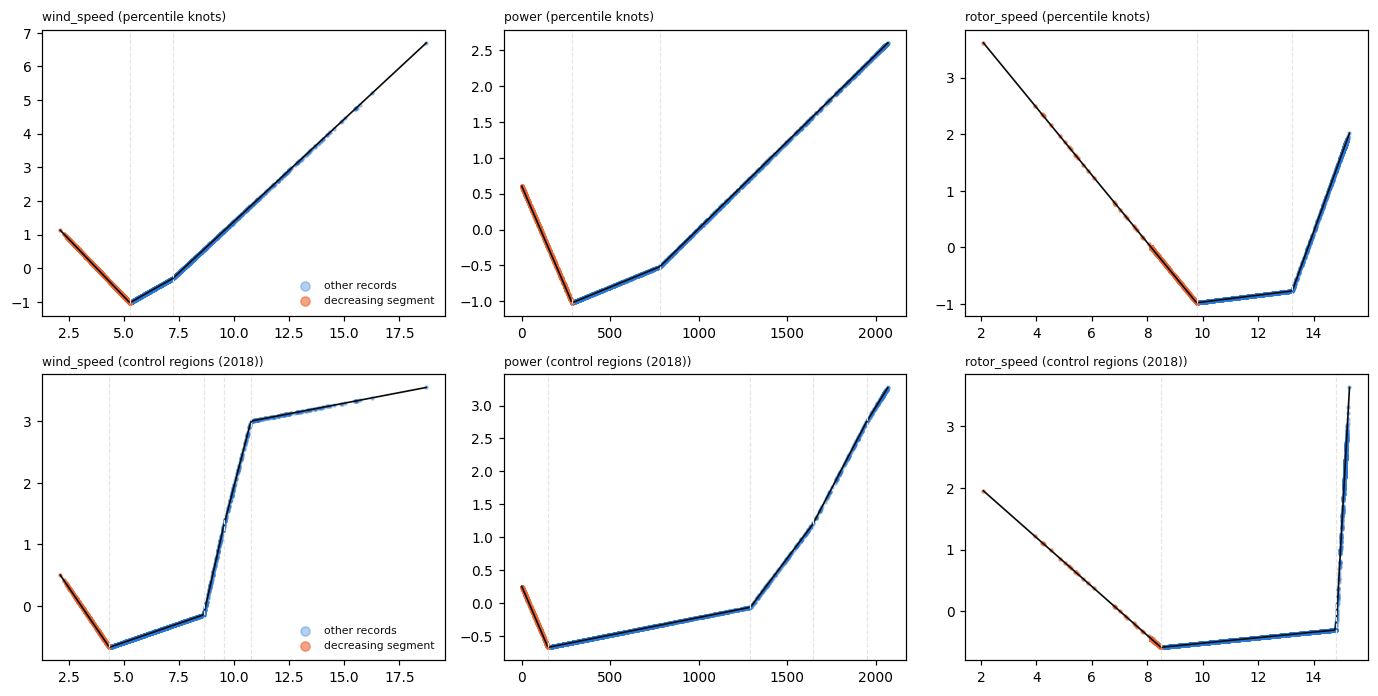

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.4))
for row, name in zip(axes, dec):
    m_ = models[name]
    for ax, v in zip(row, ("wind_speed", "power", "rotor_speed")):
        j = VARS.index(v)
        x, f = m_.variable_transformation(j)
        mask = dec[name][v][0]
        ax.plot(x, f, color=INK, lw=1.1)
        ax.scatter(X[v][~mask], m_.transformed_[~mask, j], s=4, color=BLUE, alpha=0.35, label="other records")
        ax.scatter(X[v][mask], m_.transformed_[mask, j], s=4, color=ORANGE, alpha=0.6, label="decreasing segment")
        for k in np.unique(m_.knots_[j])[1:-1] * m_.std_[j] + m_.mean_[j]:
            ax.axvline(k, color=GRID, lw=0.8, ls="--")
        ax.set_title(f"{v} ({name})", fontsize=8, loc="left")
    row[0].legend(fontsize=7, frameon=False, markerscale=3)
fig.tight_layout()
save(fig, "case_v_shapes")
plt.show()

## 6. Piecewise loadings by segment: control-region model

In [16]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    pl_c = piecewise_loadings(mc, X)
rows = []
for j, v in enumerate(VARS):
    d = pl_c[j]
    for k in range(len(d["slope_sign"])):
        rows.append({"variable": v, "segment": f"[{d['edges'][k] + 0.0:.3f}, {d['edges'][k + 1] + 0.0:.3f}]",
                     "n": int(d["n"][k]), "fewer than 50": "yes" if d["n"][k] < 50 else "",
                     "slope sign": int(d["slope_sign"][k]), "loading 1": d["loadings"][k][0], "loading 2": d["loadings"][k][1]})
pl_table = pd.DataFrame(rows)
pl_table.to_csv(RES / "case_piecewise_loadings.csv", index=False, float_format="%.4f", lineterminator="\n")
pl_table

,variable,segment,n,fewer than 50,slope sign,loading 1,loading 2
0,wind_speed,"[2.123, 4.351]",348,,-1,-0.6530,0.0121
1,wind_speed,"[4.351, 8.625]",1304,,1,0.6872,-0.2884
2,wind_speed,"[8.625, 9.553]",129,,1,0.7235,0.0959
3,wind_speed,"[9.553, 10.771]",104,,1,0.7819,0.4374
4,wind_speed,"[10.771, 18.723]",115,,1,0.4796,-0.0538
5,power,"[1.236, 149.085]",356,,-1,-0.7108,-0.1230
6,power,"[149.085, 1293.249]",1291,,1,0.7435,-0.3190
7,power,"[1293.249, 1645.916]",130,,1,0.8064,0.2670
8,power,"[1645.916, 1949.043]",108,,1,0.8311,0.3119
9,power,"[1949.043, 2069.953]",115,,1,0.5878,-0.2390


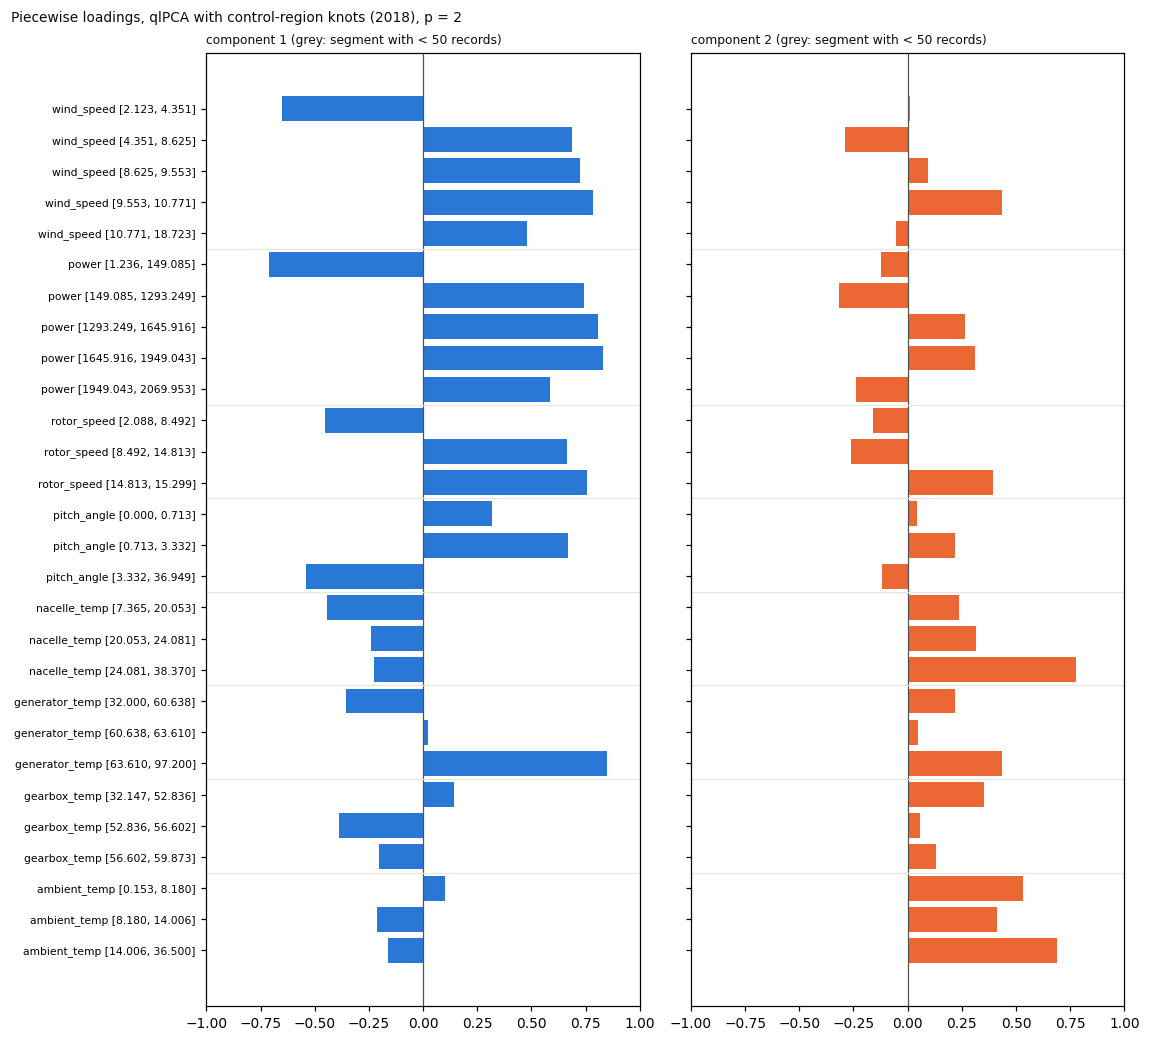

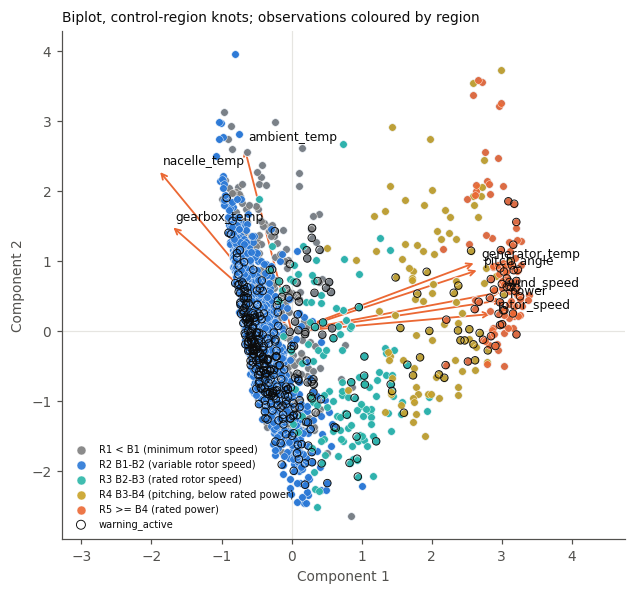

In [17]:
lab = pl_table.variable + " " + pl_table.segment
y = np.arange(len(pl_table))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 0.3 * len(pl_table) + 1.2), sharey=True)
for ax, c, col in zip(axes, ("loading 1", "loading 2"), (BLUE, ORANGE)):
    ax.barh(y, pl_table[c], color=[col if n >= 50 else GRID for n in pl_table.n])
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(c.replace("loading", "component") + " (grey: segment with < 50 records)", fontsize=8, loc="left")
    for b in np.flatnonzero(pl_table.variable.ne(pl_table.variable.shift()))[1:]:
        ax.axhline(b - 0.5, color=GRID, lw=0.8)
axes[0].set_yticks(y, lab, fontsize=7); axes[0].invert_yaxis()
fig.suptitle("Piecewise loadings, qlPCA with control-region knots (2018), p = 2", fontsize=9, x=0.01, ha="left")
fig.tight_layout()
save(fig, "case_piecewise_loadings")
plt.show()

fig, ax = plt.subplots(figsize=(6.6, 6.0))
biplot(mc, ax=ax)
for rg in REG:
    sel = (region == rg).to_numpy()
    ax.scatter(mc.scores_[sel, 0], mc.scores_[sel, 1], s=24, color=RCOL[rg], alpha=0.9, edgecolor="white", linewidth=0.3,
               label=rg, zorder=3.5)
ax.scatter(mc.scores_[warn, 0], mc.scores_[warn, 1], s=24, facecolor="none", edgecolor=INK, linewidth=0.6,
           label="warning_active", zorder=3.7)
ax.legend(fontsize=6.5, frameon=False, markerscale=1.2, loc="lower left")
ax.set_title("Biplot, control-region knots; observations coloured by region", fontsize=9, loc="left")
save(fig, "case_biplot_regimes")
plt.show()

## 7. Projection of new observations

Fit on the sampled records of January – September 2019; project October – December with `transform()`.

In [18]:
train = (time.dt.month <= 9).to_numpy()
Xtr, Xte = X[train], X[~train]
outside = ((Xte < Xtr.min()) | (Xte > Xtr.max()))
print(f"training records: {train.sum()}; projected records: {(~train).sum()}; projected records outside the training "
      f"range: {int(outside.any(axis=1).sum())} {outside.sum()[outside.sum() > 0].to_dict()}")
proj = []
for name in ("PCA", "percentile knots", "control regions (2018)"):
    m = fit(name, Xtr)
    with warnings.catch_warnings(record=True) as rec:
        warnings.simplefilter("always")
        S = m.transform(Xte)
        F_raw = m.transform_variables(Xte)
    msgs = [str(w.message) for w in rec if issubclass(w.category, ExtrapolationWarning)]
    print(f"{name}: ExtrapolationWarning: {msgs[0] if msgs else 'none issued'}")
    V = m.loadings_ / np.linalg.norm(m.loadings_, axis=0)
    proj.append({"model": name, "VAF training": m.vaf_.sum(),
                 "VAF projected, clipped": s.oos_vaf(None, m, Xte.to_numpy(), Xtr.to_numpy()),
                 "VAF projected, linear extrapolation": 100 * np.linalg.norm(F_raw @ V) ** 2 / np.linalg.norm(F_raw) ** 2,
                 "scores training": f"[{m.scores_.min():.2f}, {m.scores_.max():.2f}]",
                 "scores projected": f"[{S.min():.2f}, {S.max():.2f}]"})
proj_table = pd.DataFrame(proj).set_index("model")
proj_table.to_csv(RES / "case_projection.csv", float_format="%.4f", lineterminator="\n")
proj_table

training records: 1449; projected records: 551; projected records outside the training range: 1 {'rotor_speed': 1, 'pitch_angle': 1}
PCA: ExtrapolationWarning: 1 of 551 observation(s) fall outside the training range of variable(s) rotor_speed, pitch_angle; their transformations are extrapolated linearly from the last segment of each spline and may be unreliable (heavy tails: transform the variable, e.g. log, before fitting).


percentile knots: ExtrapolationWarning: 1 of 551 observation(s) fall outside the training range of variable(s) rotor_speed, pitch_angle; their transformations are extrapolated linearly from the last segment of each spline and may be unreliable (heavy tails: transform the variable, e.g. log, before fitting).


control regions (2018): ExtrapolationWarning: 1 of 551 observation(s) fall outside the training range of variable(s) rotor_speed, pitch_angle; their transformations are extrapolated linearly from the last segment of each spline and may be unreliable (heavy tails: transform the variable, e.g. log, before fitting).


,VAF training,"VAF projected, clipped","VAF projected, linear extrapolation",scores training,scores projected
model,,,,,
PCA,72.3051,75.0264,74.7114,"[-5.92, 3.92]","[-3.51, 2.91]"
percentile knots,80.1094,81.9298,81.8777,"[-2.68, 4.14]","[-2.26, 3.10]"
control regions (2018),83.4349,83.4862,83.4569,"[-3.37, 3.72]","[-2.37, 3.39]"


## 8. Sensitivity: without the records overlapping Warning events

The comparison of section 4 repeated on the sample without the `warning_active` records (same blocks construction).

In [19]:
vaf_nw, _, _ = vaf_table(X[~warn].reset_index(drop=True), f"without warning_active ({int((~warn).sum())} records)")
sens = pd.concat([vaf, vaf_nw])
sens.to_csv(RES / "case_vaf_sensitivity.csv", index=False, float_format="%.4f", lineterminator="\n")
sens.pivot(index="model", columns="data", values=["VAF in sample", "VAF out of sample", "paired gain"]).round(2).reindex(list(SPECS))

VAF in sample                                       VAF out of sample                                            paired gain                                      
data                             all 2000 records without warning_active (1635 records)  all 2000 records without warning_active (1635 records) all 2000 records without warning_active (1635 records)
model                                                                                                                                                                                                 
PCA                                         72.57                                 73.14             71.95                                 73.13              NaN                                   NaN
percentile knots                            80.63                                 80.81             80.48                                 80.59             8.53                                  7.46
percentile knots, monotone                  78.87                                 79.29             78.34                                 78.69             6.39                                  5.56
control regions (2018)                      83.45                                 83.68             82.91                                 82.95            10.97                                  9.82
control regions (2018), monotone            82.64                                 82.97             81.97                                 82.11            10.02                                  8.98
datasheet (reference)                       76.15                                 76.58             75.89                                 76.56             3.94                                  3.43

## 9. Conclusions

Computed from the cells above.

In [20]:
L = []
L.append(f"1. Data: 2019, {info['records_after_filtering']} records after filtering (Stop/Communication, Power <= 0, "
         f"missing values; {mv['records_with_missing']} records had missing values, all removed); "
         f"{info['records_after_filtering_with_warning_active']} filtered records overlap Warning events (kept, flagged); "
         f"sample of 2000 with {int(warn.sum())} warning_active; 8 variables.")
L.append("2. Control-region boundaries (2018 medians, 0.5 m/s classes, 5 % thresholds), wind speed: " +
         ", ".join(f"{k} {w:.2f} m/s" for k, w in B.items()) + ".")
L.append("3. VAF, p = 2, in sample / out of sample / paired gain over PCA (se):")
for _, r in vaf.iterrows():
    g = "" if r.model == "PCA" else f" / {r['paired gain']:.2f} ({r['se (gain)']:.2f})"
    L.append(f"   {r.model}: {r['VAF in sample']:.2f} / {r['VAF out of sample']:.2f}{g}")
L.append("4. Segments with fewer than 50 records: " + ", ".join(
    f"{k} {v}" for k, v in seg.groupby("model")["fewer than 50"].apply(lambda x: (x == "yes").sum()).items()) + ".")
kd = knot_dist.dropna(subset=["percentile knot"])
L.append("5. Distance from each percentile knot to the nearest control-region knot (sd of 2019): " + ", ".join(
    f"{r.variable} {r['percentile knot']:.2f}: {r['distance (sd)']:.2f}" for _, r in kd.iterrows()) + ".")
for name in dec:
    L.append(f"6. {name}: decreasing segments " + (", ".join(
        f"{v} {segs} ({m.sum()} records, {int((m & warn).sum())} warning_active)" for v, (m, segs) in dec[name].items() if segs) or "none") + ".")
L.append("7. Projection Oct-Dec from Jan-Sep, VAF clipped / linear extrapolation: " + "; ".join(
    f"{k} {r['VAF projected, clipped']:.2f} / {r['VAF projected, linear extrapolation']:.2f}" for k, r in proj_table.iterrows()) + ".")
nw = vaf_nw.set_index("model")
L.append("8. Without warning_active records, paired gain over PCA: " + "; ".join(
    f"{k} {nw.loc[k, 'paired gain']:.2f} ({nw.loc[k, 'se (gain)']:.2f})" for k in SPECS if k != "PCA") + ".")
print("\n".join(L))

1. Data: 2019, 45567 records after filtering (Stop/Communication, Power <= 0, missing values; 2428 records had missing values, all removed); 8677 filtered records overlap Warning events (kept, flagged); sample of 2000 with 365 warning_active; 8 variables.
2. Control-region boundaries (2018 medians, 0.5 m/s classes, 5 % thresholds), wind speed: B1 4.35 m/s, B2 8.62 m/s, B3 9.55 m/s, B4 10.77 m/s.
3. VAF, p = 2, in sample / out of sample / paired gain over PCA (se):
   PCA: 72.57 / 71.95
   percentile knots: 80.63 / 80.48 / 8.53 (1.97)
   percentile knots, monotone: 78.87 / 78.34 / 6.39 (1.01)
   control regions (2018): 83.45 / 82.91 / 10.97 (2.15)
   control regions (2018), monotone: 82.64 / 81.97 / 10.02 (1.80)
   datasheet (reference): 76.15 / 75.89 / 3.94 (0.32)
4. Segments with fewer than 50 records: control regions (2018) 0, datasheet (reference) 3, percentile knots 0.
5. Distance from each percentile knot to the nearest control-region knot (sd of 2019): wind_speed 5.28: 0.38, wind

### References

* Lavado, N. & Calapez, T. (2011). Principal Components Analysis with Spline Optimal Transformations for Continuous
  Data. *IAENG International Journal of Applied Mathematics*, 41(4), 367–375. (`lavado2011ijam`)
* Lavado, N. (2012). *Extensões via splines da Análise em Componentes Principais*. PhD thesis, ISCTE-IUL. (`lavado2012phd`)
* Plumley, C. & Takeuchi, R. *Kelmarsh wind farm data*. Zenodo, doi:10.5281/zenodo.16807551, CC-BY-4.0. (`plumley2025kelmarsh`)
* Senvion. *MM92 technical data*, senvion.com product page, archived 2020-04-02. (`senvion2020mm92`)